# LIFAD: From Release to Legacy
## Deep Python Analysis

This notebook follows the album from its 2009 commercial launch to its present-day digital and live footprint.

The analysis is intentionally built around questions rather than isolated charts. Spotify scale, current streaming momentum, Last.fm reach, repeat listening, live persistence, chart history and certifications are treated as different signals instead of being collapsed into one definition of popularity.

**Working principle:** undocumented live values stay missing. They are never silently converted to zero.

In [1]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

# the notebook works from the project folder or from a nearby data subfolder
PROJECT_DIR = Path.cwd()
VISUAL_DIR = PROJECT_DIR / "visuals"
VISUAL_DIR.mkdir(exist_ok=True)

def find_file(filename):
    candidates = [
        PROJECT_DIR / filename,
        PROJECT_DIR / "data" / filename,
        PROJECT_DIR.parent / filename,
    ]

    for path in candidates:
        if path.exists():
            return path

    raise FileNotFoundError(
        f"{filename} was not found. place the notebook beside the csv files "
        "or move the csv files into a data/ folder."
    )

track_path = find_file("lifad_tracks_new.csv")
chart_path = find_file("lifad_charts.csv")
cert_path = find_file("lifad_certifications.csv")

tracks = pd.read_csv(track_path)
charts = pd.read_csv(chart_path)
certs = pd.read_csv(cert_path)

print("tracks:", tracks.shape)
print("charts:", charts.shape)
print("certifications:", certs.shape)
print("visual folder:", VISUAL_DIR)

tracks: (16, 30)
charts: (18, 15)
certifications: (13, 12)
visual folder: c:\Users\anarrasulzada\Desktop\LIFAD\visuals


In [2]:
# dates become proper datetime values before recency-based work begins
date_columns = [
    "first_release",
    "live_debut",
    "last_performed",
    "retrieved_at",
    "lastfm_retrieved_at",
    "spotify_retrieved_at",
]

for column in date_columns:
    if column in tracks.columns:
        tracks[column] = pd.to_datetime(tracks[column], errors="coerce")

if "first_chart_date" in charts.columns:
    charts["first_chart_date"] = pd.to_datetime(
        charts["first_chart_date"],
        errors="coerce"
    )

# numeric coercion keeps later calculations predictable
track_numeric = [
    "album_order",
    "duration_sec",
    "bpm",
    "live_count",
    "lastfm_listeners",
    "lastfm_playcount",
    "scrobbles_per_listener",
    "spotify_streams",
    "spotify_daily_streams",
]

for column in track_numeric:
    if column in tracks.columns:
        tracks[column] = pd.to_numeric(
            tracks[column],
            errors="coerce"
        )

chart_numeric = [
    "peak_position",
    "weeks_on_chart",
]

for column in chart_numeric:
    if column in charts.columns:
        charts[column] = pd.to_numeric(
            charts[column],
            errors="coerce"
        )

cert_numeric = [
    "certification_multiplier",
    "certified_units",
]

for column in cert_numeric:
    if column in certs.columns:
        certs[column] = pd.to_numeric(
            certs[column],
            errors="coerce"
        )

# undocumented live history remains missing rather than becoming a false zero
tracks["live_documented"] = tracks["live_count"].notna()

# shorter display names keep annotations readable without changing the original field
tracks["display_name"] = tracks["track_name"].replace({
    "Roter Sand (Orchester Version)": "Roter Sand (Orch.)",
    "Liebe ist für alle da": "Liebe ist für alle da",
})

def minmax(series):
    values = pd.to_numeric(series, errors="coerce")
    low = values.min()
    high = values.max()

    if pd.isna(low) or pd.isna(high) or high == low:
        return pd.Series(np.nan, index=series.index)

    return (values - low) / (high - low)

def save_figure(fig, filename):
    path = VISUAL_DIR / filename
    fig.savefig(
        path,
        dpi=220,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )
    print(f"saved: {path.name}")

## Data integrity before interpretation

A small catalogue can make individual records unusually influential, so basic validation matters more than the row count suggests. The checks below focus on duplicate tracks, missing analytical fields and the distinction between missing live evidence and a genuine zero.

In [3]:
# a compact audit exposes issues before they leak into later conclusions
quality_summary = pd.DataFrame({
    "dataset": ["tracks", "charts", "certifications"],
    "rows": [len(tracks), len(charts), len(certs)],
    "duplicate_rows": [
        tracks.duplicated().sum(),
        charts.duplicated().sum(),
        certs.duplicated().sum(),
    ],
    "missing_cells": [
        tracks.isna().sum().sum(),
        charts.isna().sum().sum(),
        certs.isna().sum().sum(),
    ],
})

display(quality_summary)

critical_track_fields = [
    "track_name",
    "spotify_streams",
    "spotify_daily_streams",
    "lastfm_listeners",
    "lastfm_playcount",
    "scrobbles_per_listener",
]

display(
    tracks[critical_track_fields]
    .isna()
    .sum()
    .rename("missing")
    .to_frame()
)

print(
    "documented live counts:",
    int(tracks["live_documented"].sum()),
    "/",
    len(tracks)
)

,dataset,rows,duplicate_rows,missing_cells
0,tracks,16,0,28
1,charts,18,0,15
2,certifications,13,0,2


,missing
track_name,0
spotify_streams,0
spotify_daily_streams,0
lastfm_listeners,0
lastfm_playcount,0
scrobbles_per_listener,0


documented live counts: 9 / 16


## 1. Chart peak and chart longevity: two different versions of success

A high debut captures intensity at release, while weeks on chart reflect staying power. Plotting both dimensions together prevents a No. 1 position from automatically being treated as the only meaningful outcome.

saved: 01_chart_performance_matrix.png


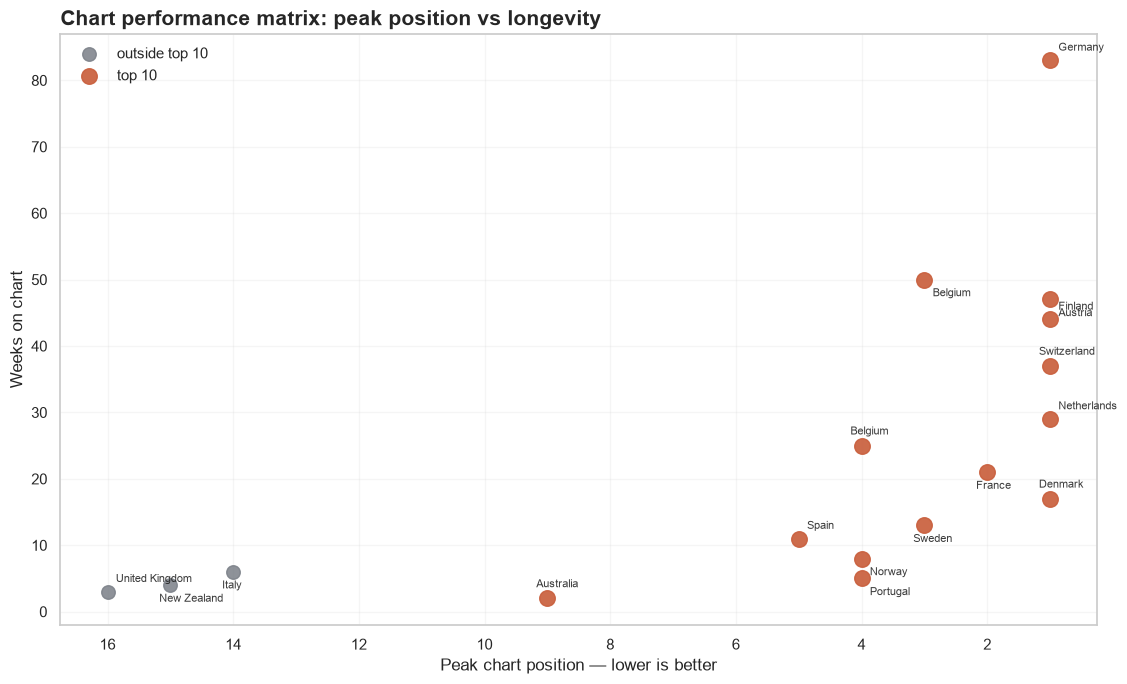

In [4]:
# rows without a documented chart duration stay outside the longevity plot
chart_plot = charts.dropna(
    subset=["peak_position", "weeks_on_chart"]
).copy()

fig, ax = plt.subplots(figsize=(11.5, 7))

top10_mask = chart_plot["peak_position"] <= 10

ax.scatter(
    chart_plot.loc[~top10_mask, "peak_position"],
    chart_plot.loc[~top10_mask, "weeks_on_chart"],
    s=95,
    alpha=0.85,
    color="#7a7f87",
    label="outside top 10",
)

ax.scatter(
    chart_plot.loc[top10_mask, "peak_position"],
    chart_plot.loc[top10_mask, "weeks_on_chart"],
    s=125,
    alpha=0.92,
    color="#c95f3d",
    label="top 10",
)

offsets = [(6, 7), (6, -12), (-8, 8), (-8, -12)]

for i, row in chart_plot.reset_index(drop=True).iterrows():
    label = textwrap.fill(str(row["country"]), width=16)
    dx, dy = offsets[i % len(offsets)]
    ax.annotate(
        label,
        (row["peak_position"], row["weeks_on_chart"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8,
        alpha=0.9,
    )

ax.set_title(
    "Chart performance matrix: peak position vs longevity",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.set_xlabel("Peak chart position — lower is better")
ax.set_ylabel("Weeks on chart")
ax.invert_xaxis()
ax.legend(frameon=False)
ax.grid(alpha=0.18)

fig.tight_layout()
save_figure(fig, "01_chart_performance_matrix.png")
plt.show()

## 2. A No. 1 peak does not automatically answer the longevity question

Separating No. 1 markets from the rest gives a direct check on whether the strongest launch positions also remained visible for longer. With only a small set of markets, the result is descriptive rather than a population-level claim.

In [5]:
# medians reduce the influence of unusually long chart runs
number_one_summary = (
    charts.assign(is_number_one=charts["peak_position"].eq(1))
    .groupby("is_number_one", dropna=False)
    .agg(
        markets=("country", "size"),
        median_weeks=("weeks_on_chart", "median"),
        mean_weeks=("weeks_on_chart", "mean"),
        max_weeks=("weeks_on_chart", "max"),
    )
    .rename(index={False: "other peaks", True: "No. 1"})
)

display(number_one_summary)

,markets,median_weeks,mean_weeks,max_weeks
is_number_one,,,,
other peaks,12,8.000,13.455,50.000
No. 1,6,40.500,42.833,83.000


## 3. International reach can be summarized without reducing every market to the same story

Rather than focusing on one country, this view measures how widely the album entered strong chart positions and how much of the observed market set reached the Top 10 or No. 1.

In [6]:
# headline indicators describe breadth while preserving the original market records
chart_reach = pd.Series({
    "chart records": len(charts),
    "unique countries": charts["country"].nunique(),
    "No. 1 records": charts["peak_position"].eq(1).sum(),
    "Top 10 records": charts["peak_position"].le(10).sum(),
    "Top 20 records": charts["peak_position"].le(20).sum(),
    "median peak": charts["peak_position"].median(),
    "median weeks": charts["weeks_on_chart"].median(),
    "longest run": charts["weeks_on_chart"].max(),
})

display(chart_reach.to_frame("value"))

,value
chart records,18.000
unique countries,17.000
No. 1 records,6.000
Top 10 records,14.000
Top 20 records,18.000
median peak,3.500
median weeks,17.000
longest run,83.000


## 4. Certifications add a second commercial lens

Chart data describe position and duration; certifications record a different kind of milestone. The bridge below joins markets only where the names can be matched safely, while Europe-level certification remains separate from individual countries.

In [7]:
# light normalization handles common naming differences without inventing matches
def normalize_market(value):
    if pd.isna(value):
        return np.nan

    cleaned = str(value).strip()

    aliases = {
        "UK": "United Kingdom",
        "U.K.": "United Kingdom",
        "USA": "United States",
        "US": "United States",
        "U.S.": "United States",
    }

    return aliases.get(cleaned, cleaned)

chart_market = (
    charts.assign(market_key=charts["country"].map(normalize_market))
    .groupby("market_key", as_index=False)
    .agg(
        best_peak=("peak_position", "min"),
        longest_chart_run=("weeks_on_chart", "max"),
        chart_entries=("country", "size"),
    )
)

cert_market = certs.copy()
cert_market["market_key"] = cert_market["region"].map(normalize_market)

cert_market["certification_display"] = (
    cert_market["certification_multiplier"]
    .fillna(1)
    .astype("Int64")
    .astype(str)
    .replace("<NA>", "")
    + "× "
    + cert_market["certification"].fillna("")
)

market_bridge = chart_market.merge(
    cert_market[
        [
            "market_key",
            "certification_display",
            "certified_units",
            "unit_basis",
        ]
    ],
    on="market_key",
    how="left",
)

display(
    market_bridge.sort_values(
        ["best_peak", "longest_chart_run"],
        ascending=[True, False]
    )
)

print(
    "chart markets with a matched certification:",
    int(market_bridge["certification_display"].notna().sum()),
    "/",
    len(market_bridge)
)

,market_key,best_peak,longest_chart_run,chart_entries,certification_display,certified_units,unit_basis
6,Germany,1,83.000,1,7× 7× Gold,"700,000.000",sales + streaming
1,Austria,1,47.000,1,1× Platinum,"20,000.000",certification sales
4,Finland,1,44.000,1,1× Platinum,"24,843.000",reported sales
14,Switzerland,1,37.000,1,1× Platinum,"30,000.000",shipments
8,Netherlands,1,29.000,1,NaN,NaN,NaN
3,Denmark,1,17.000,1,1× Gold,"15,000.000",shipments
5,France,2,21.000,1,1× Gold,"50,000.000",certification sales
2,Belgium,3,50.000,2,1× Gold,"15,000.000",certification sales
13,Sweden,3,13.000,1,1× Gold,"20,000.000",sales + streaming
10,Norway,4,8.000,1,NaN,NaN,NaN


chart markets with a matched certification: 9 / 17


## 5. Is the album's Spotify footprint broad, or carried by a few tracks?

A catalogue can have hundreds of millions of streams and still depend heavily on a small number of songs. A Pareto view exposes that concentration by pairing track-level streams with cumulative share.

saved: 02_spotify_concentration_pareto.png


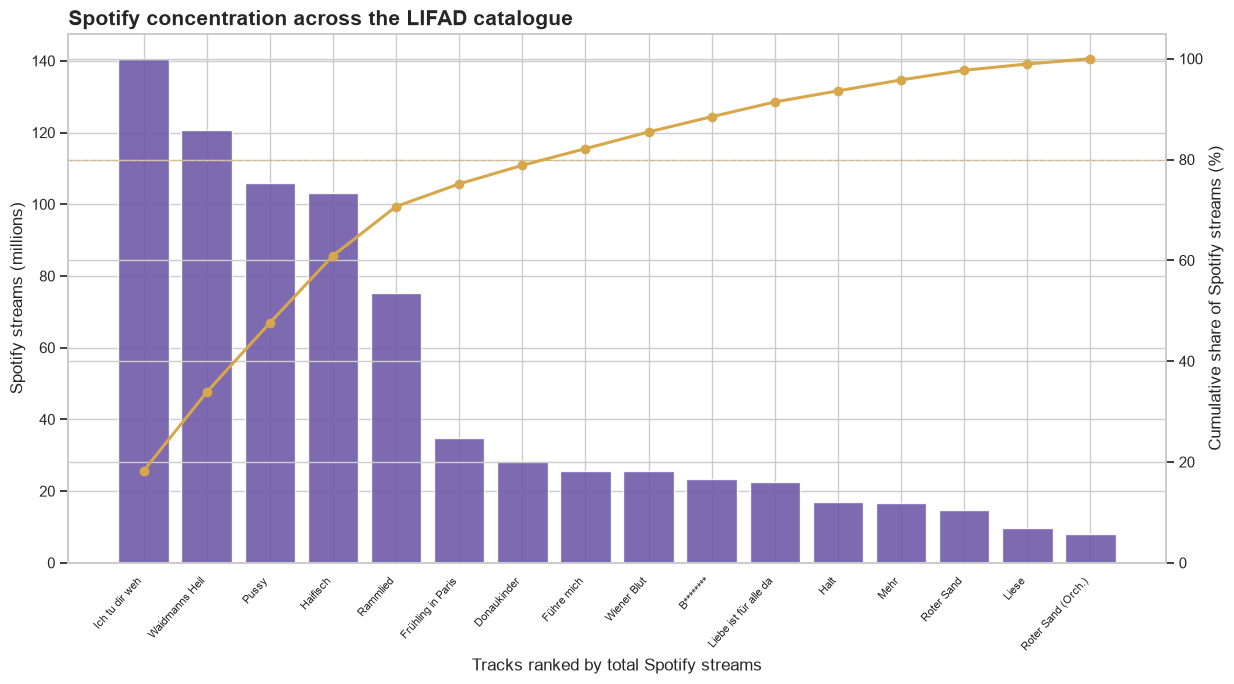

top 1 share: 18.2%
top 3 share: 47.6%
top 5 share: 70.7%


In [8]:
# descending order turns cumulative share into a direct concentration curve
spotify_ranked = (
    tracks[["display_name", "spotify_streams"]]
    .sort_values("spotify_streams", ascending=False)
    .reset_index(drop=True)
)

spotify_ranked["stream_share"] = (
    spotify_ranked["spotify_streams"]
    / spotify_ranked["spotify_streams"].sum()
)

spotify_ranked["cumulative_share"] = (
    spotify_ranked["stream_share"].cumsum()
)

fig, ax1 = plt.subplots(figsize=(12.5, 7))

x = np.arange(len(spotify_ranked))

ax1.bar(
    x,
    spotify_ranked["spotify_streams"] / 1_000_000,
    color="#6f5aa8",
    alpha=0.9,
)

ax1.set_ylabel("Spotify streams (millions)")
ax1.set_xlabel("Tracks ranked by total Spotify streams")
ax1.set_xticks(x)
ax1.set_xticklabels(
    spotify_ranked["display_name"],
    rotation=48,
    ha="right",
    fontsize=8,
)

ax2 = ax1.twinx()

ax2.plot(
    x,
    spotify_ranked["cumulative_share"] * 100,
    color="#d6a84b",
    marker="o",
    linewidth=2.2,
)

ax2.axhline(
    80,
    color="#d6a84b",
    linestyle="--",
    linewidth=1,
    alpha=0.5,
)

ax2.set_ylabel("Cumulative share of Spotify streams (%)")
ax2.set_ylim(0, 105)

ax1.set_title(
    "Spotify concentration across the LIFAD catalogue",
    loc="left",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout()
save_figure(fig, "02_spotify_concentration_pareto.png")
plt.show()

for n in [1, 3, 5]:
    share = spotify_ranked.loc[: n - 1, "stream_share"].sum()
    print(f"top {n} share: {share:.1%}")

## 6. Spotify and Last.fm may agree on scale without agreeing on order

Absolute values cannot be compared directly across the two platforms, but catalogue rank can. A slopegraph makes every change in position visible and keeps platform differences interpretable.

saved: 03_cross_platform_rank_shift.png


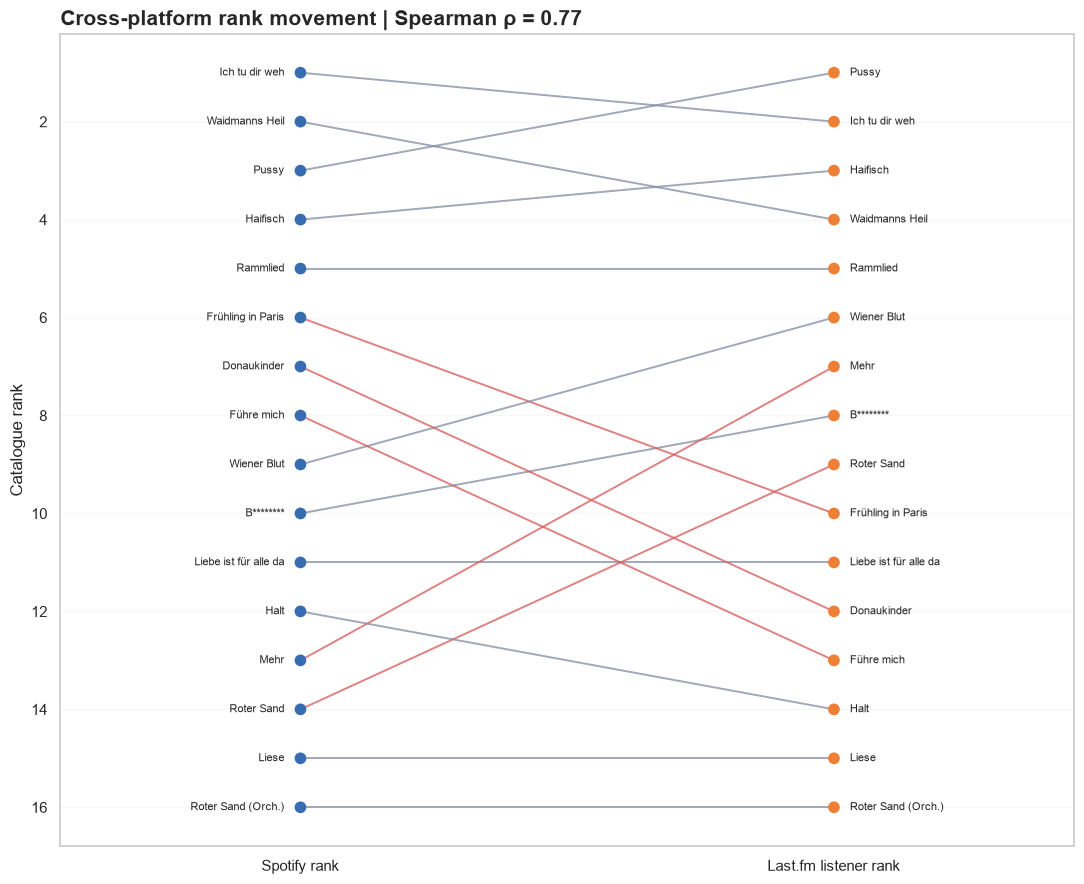

,display_name,spotify_streams,lastfm_listeners,spotify_rank,lastfm_rank,rank_change
9,Mehr,16799428,190766,13.000,7.000,-6.000
12,Donaukinder,28411732,140357,7.000,12.000,5.000
10,Roter Sand,14750579,186955,14.000,9.000,-5.000
11,Führe mich,25564873,124972,8.000,13.000,5.000
5,Frühling in Paris,34726953,175592,6.000,10.000,4.000
6,Wiener Blut,25501330,204105,9.000,6.000,-3.000
2,Waidmanns Heil,120653465,317595,2.000,4.000,2.000
4,B********,23407374,189481,10.000,8.000,-2.000


In [9]:
# ranking within the same sixteen tracks avoids cross-platform unit problems
rank_shift = tracks[
    [
        "display_name",
        "spotify_streams",
        "lastfm_listeners",
    ]
].copy()

rank_shift["spotify_rank"] = (
    rank_shift["spotify_streams"]
    .rank(method="min", ascending=False)
)

rank_shift["lastfm_rank"] = (
    rank_shift["lastfm_listeners"]
    .rank(method="min", ascending=False)
)

rank_shift["rank_change"] = (
    rank_shift["lastfm_rank"]
    - rank_shift["spotify_rank"]
)

rank_corr = (
    rank_shift[
        ["spotify_streams", "lastfm_listeners"]
    ]
    .corr(method="spearman")
    .iloc[0, 1]
)

fig, ax = plt.subplots(figsize=(11, 9))

for _, row in rank_shift.iterrows():
    movement = abs(row["rank_change"])

    line_color = (
        "#d65f5f"
        if movement >= 4
        else "#8590a6"
    )

    ax.plot(
        [0, 1],
        [row["spotify_rank"], row["lastfm_rank"]],
        color=line_color,
        linewidth=1.4,
        alpha=0.78,
    )

    ax.scatter(
        [0, 1],
        [row["spotify_rank"], row["lastfm_rank"]],
        color=["#386cb0", "#ef7f35"],
        s=55,
        zorder=3,
    )

    ax.text(
        -0.03,
        row["spotify_rank"],
        row["display_name"],
        ha="right",
        va="center",
        fontsize=8,
    )

    ax.text(
        1.03,
        row["lastfm_rank"],
        row["display_name"],
        ha="left",
        va="center",
        fontsize=8,
    )

ax.set_xlim(-0.45, 1.45)
ax.set_ylim(16.8, 0.2)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Spotify rank", "Last.fm listener rank"])
ax.set_ylabel("Catalogue rank")
ax.set_title(
    f"Cross-platform rank movement | Spearman ρ = {rank_corr:.2f}",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.grid(axis="y", alpha=0.15)
ax.grid(axis="x", visible=False)

fig.tight_layout()
save_figure(fig, "03_cross_platform_rank_shift.png")
plt.show()

display(
    rank_shift.sort_values(
        "rank_change",
        key=lambda s: s.abs(),
        ascending=False
    ).head(8)
)

## 7. Reach and listening depth are not the same behaviour

A large listener base tells us how widely a track has travelled; scrobbles per listener capture how repeatedly that audience returns. The median lines form four descriptive quadrants rather than rigid audience segments.

saved: 04_reach_engagement_quadrant.png


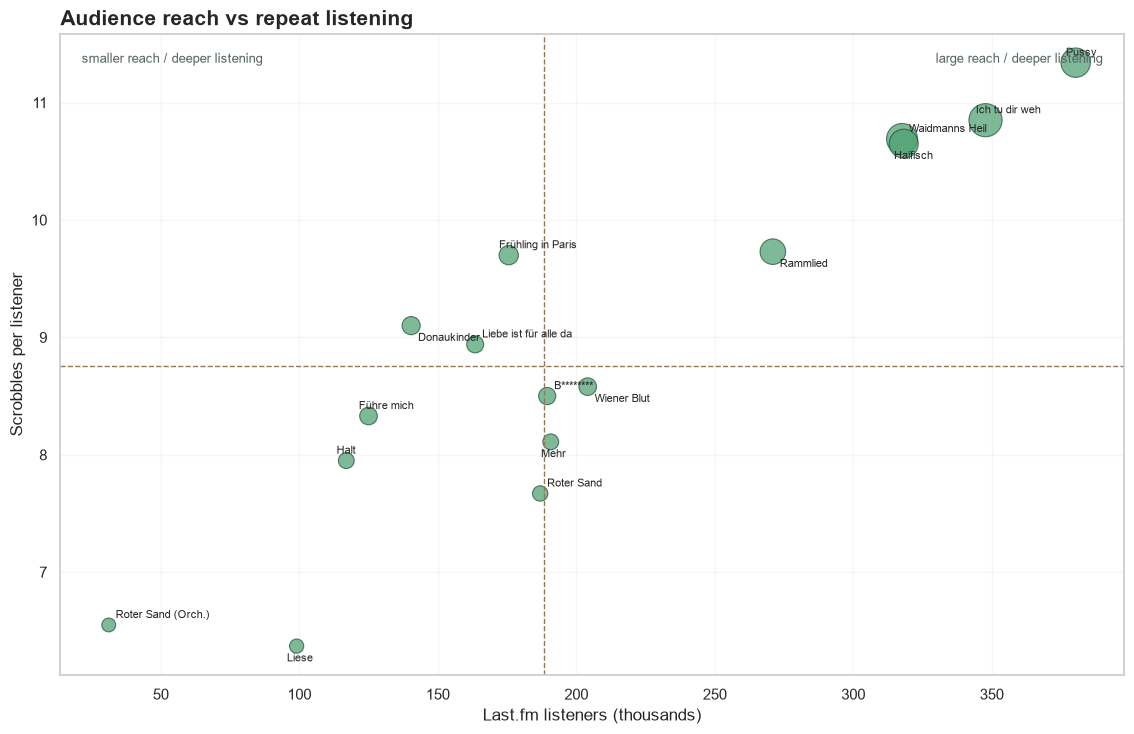

In [10]:
# median thresholds keep the quadrant definition tied to this album only
reach_mid = tracks["lastfm_listeners"].median()
engagement_mid = tracks["scrobbles_per_listener"].median()

bubble_size = (
    70
    + 500
    * tracks["spotify_streams"]
    / tracks["spotify_streams"].max()
)

fig, ax = plt.subplots(figsize=(11.5, 7.5))

ax.scatter(
    tracks["lastfm_listeners"] / 1_000,
    tracks["scrobbles_per_listener"],
    s=bubble_size,
    color="#4c9f70",
    edgecolor="#1f4f38",
    linewidth=0.8,
    alpha=0.72,
)

ax.axvline(
    reach_mid / 1_000,
    color="#927a56",
    linestyle="--",
    linewidth=1,
)

ax.axhline(
    engagement_mid,
    color="#927a56",
    linestyle="--",
    linewidth=1,
)

for i, row in tracks.reset_index(drop=True).iterrows():
    dx = 5 if i % 2 == 0 else -7
    dy = 5 if i % 3 else -11

    ax.annotate(
        row["display_name"],
        (
            row["lastfm_listeners"] / 1_000,
            row["scrobbles_per_listener"],
        ),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8,
    )

ax.text(
    0.02,
    0.97,
    "smaller reach / deeper listening",
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    color="#56645d",
)

ax.text(
    0.98,
    0.97,
    "large reach / deeper listening",
    transform=ax.transAxes,
    va="top",
    ha="right",
    fontsize=9,
    color="#56645d",
)

ax.set_title(
    "Audience reach vs repeat listening",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.set_xlabel("Last.fm listeners (thousands)")
ax.set_ylabel("Scrobbles per listener")
ax.grid(alpha=0.17)

fig.tight_layout()
save_figure(fig, "04_reach_engagement_quadrant.png")
plt.show()

## 8. Deep cuts can emerge from behaviour rather than reputation

Tracks below the album's median listener reach but above its median repeat-listening rate deserve a closer look. This definition is deliberately local to LIFAD and does not claim a universal threshold for a “cult track”.

In [11]:
# the deep-cut flag combines lower reach with above-median listening depth
deep_cuts = (
    tracks.loc[
        (tracks["lastfm_listeners"] < reach_mid)
        & (tracks["scrobbles_per_listener"] > engagement_mid),
        [
            "track_name",
            "lastfm_listeners",
            "lastfm_playcount",
            "scrobbles_per_listener",
            "spotify_streams",
        ],
    ]
    .sort_values(
        "scrobbles_per_listener",
        ascending=False
    )
)

display(deep_cuts)

,track_name,lastfm_listeners,lastfm_playcount,scrobbles_per_listener,spotify_streams
5,Frühling in Paris,175592,1703375,9.700,34726953
12,Donaukinder,140357,1277753,9.100,28411732
8,Liebe ist für alle da,163478,1460791,8.940,22550422


## 9. Historical Spotify scale can be separated from present-day activity

Total streams accumulate over years; daily streams are a snapshot of current movement. Their association tells us whether the catalogue's established hierarchy still resembles its present listening pattern.

In [12]:
# logarithms reduce the dominance of the largest tracks without changing their order
stream_relationship = (
    tracks[
        ["spotify_streams", "spotify_daily_streams"]
    ]
    .apply(np.log10)
    .corr(method="spearman")
    .iloc[0, 1]
)

print(
    "spearman relationship between total and daily spotify activity:",
    f"{stream_relationship:.3f}"
)

historical_current = tracks[
    [
        "track_name",
        "spotify_streams",
        "spotify_daily_streams",
    ]
].copy()

historical_current["total_rank"] = (
    historical_current["spotify_streams"]
    .rank(ascending=False, method="min")
)

historical_current["daily_rank"] = (
    historical_current["spotify_daily_streams"]
    .rank(ascending=False, method="min")
)

historical_current["rank_gap"] = (
    historical_current["daily_rank"]
    - historical_current["total_rank"]
)

display(
    historical_current.sort_values(
        "rank_gap",
        key=lambda s: s.abs(),
        ascending=False
    )
)

spearman relationship between total and daily spotify activity: 0.982


,track_name,spotify_streams,spotify_daily_streams,total_rank,daily_rank,rank_gap
6,Wiener Blut,25501330,"3,651.000",9.000,11.000,2.000
3,Haifisch,102998020,"19,492.000",4.000,3.000,-1.000
4,B********,23407374,"5,163.000",10.000,9.000,-1.000
5,Frühling in Paris,34726953,"8,119.000",6.000,7.000,1.000
7,Pussy,106049284,"18,121.000",3.000,4.000,1.000
13,Halt,16991194,"3,276.000",12.000,13.000,1.000
9,Mehr,16799428,"3,555.000",13.000,12.000,-1.000
8,Liebe ist für alle da,22550422,"4,336.000",11.000,10.000,-1.000
12,Donaukinder,28411732,"12,297.000",7.000,6.000,-1.000
1,Ich tu dir weh,140581885,"31,132.000",1.000,1.000,0.000


## 10. Relative momentum asks a different question from raw daily streams

Dividing the current daily count by accumulated Spotify streams gives a small but useful catalogue-level rate: how much present activity exists relative to the track's historical base. The value is interpreted comparatively, not as a forecast.

saved: 05_current_momentum_lollipop.png


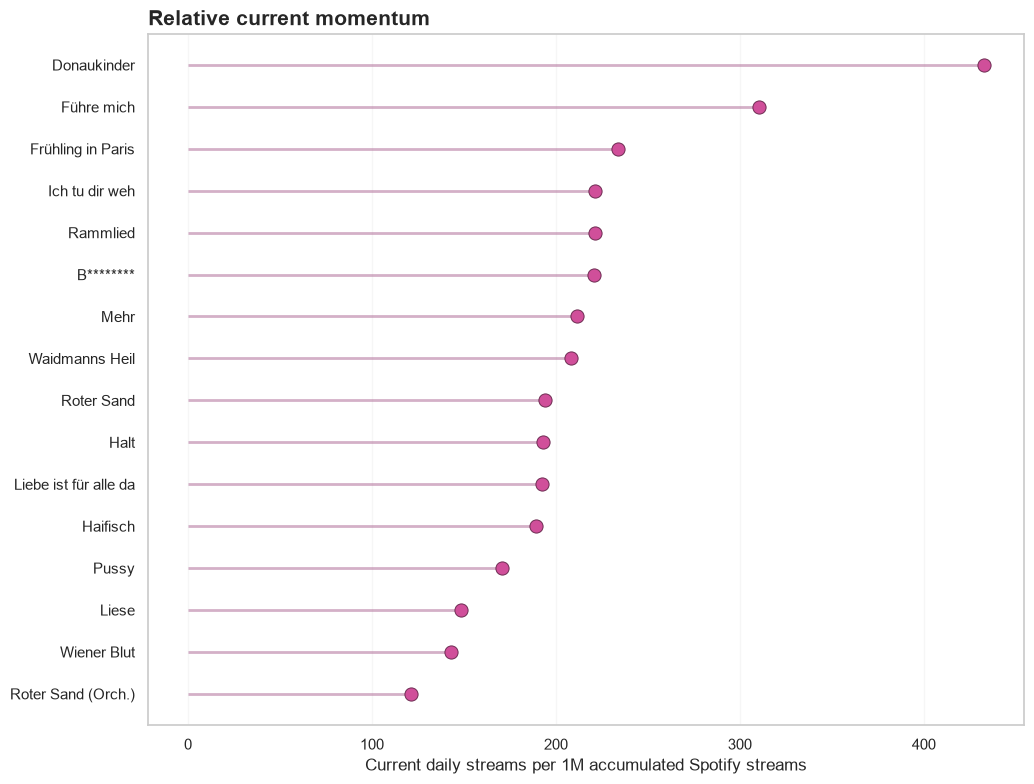

In [13]:
# scaling by one million makes the ratio easier to read on the chart
tracks["daily_per_million_streams"] = (
    tracks["spotify_daily_streams"]
    / tracks["spotify_streams"]
    * 1_000_000
)

momentum = (
    tracks[
        ["display_name", "daily_per_million_streams"]
    ]
    .sort_values(
        "daily_per_million_streams",
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(10.5, 8))

y = np.arange(len(momentum))

ax.hlines(
    y,
    xmin=0,
    xmax=momentum["daily_per_million_streams"],
    color="#b16f9a",
    linewidth=2,
    alpha=0.55,
)

ax.scatter(
    momentum["daily_per_million_streams"],
    y,
    s=90,
    color="#d04f9a",
    edgecolor="#6d2b51",
    linewidth=0.7,
    zorder=3,
)

ax.set_yticks(y)
ax.set_yticklabels(momentum["display_name"])
ax.set_xlabel("Current daily streams per 1M accumulated Spotify streams")
ax.set_ylabel("")
ax.set_title(
    "Relative current momentum",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.grid(axis="x", alpha=0.16)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "05_current_momentum_lollipop.png")
plt.show()

## 11. Some tracks are more active today than their historical scale would predict

A log-linear baseline estimates expected daily activity from accumulated Spotify streams. The residual is not a causal measure; it simply highlights songs sitting above or below the album's own historical-current relationship.

saved: 06_streaming_momentum_residuals.png


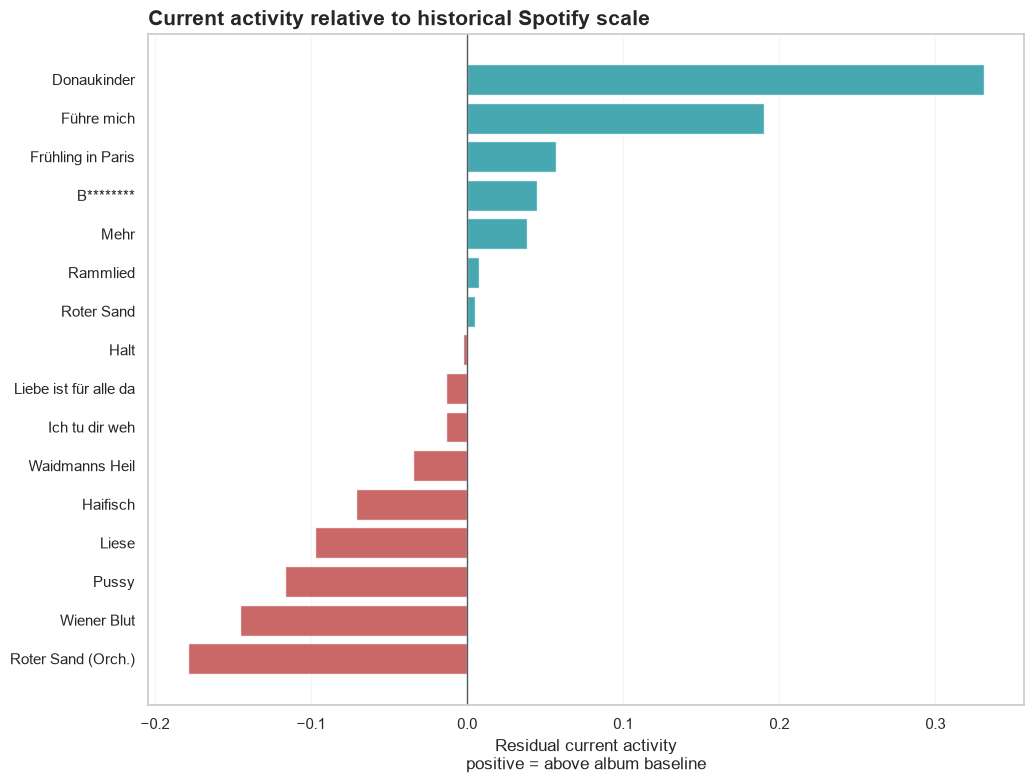

,track_name,spotify_streams,spotify_daily_streams,momentum_residual
12,Donaukinder,28411732,"12,297.000",0.331
11,Führe mich,25564873,"7,933.000",0.190
5,Frühling in Paris,34726953,"8,119.000",0.057
4,B********,23407374,"5,163.000",0.045
9,Mehr,16799428,"3,555.000",0.038
0,Rammlied,75208799,"16,645.000",0.007
10,Roter Sand,14750579,"2,864.000",0.005
13,Halt,16991194,"3,276.000",-0.003
8,Liebe ist für alle da,22550422,"4,336.000",-0.013
1,Ich tu dir weh,140581885,"31,132.000",-0.013


In [14]:
# a log-log fit produces an expected daily level for each track
log_total = np.log10(tracks["spotify_streams"])
log_daily = np.log10(tracks["spotify_daily_streams"])

slope, intercept = np.polyfit(
    log_total,
    log_daily,
    1
)

tracks["expected_log_daily"] = (
    intercept
    + slope * log_total
)

tracks["momentum_residual"] = (
    log_daily
    - tracks["expected_log_daily"]
)

residuals = tracks[
    ["display_name", "momentum_residual"]
].sort_values("momentum_residual")

fig, ax = plt.subplots(figsize=(10.5, 8))

bar_colors = np.where(
    residuals["momentum_residual"] >= 0,
    "#2e9ca6",
    "#c35353",
)

ax.barh(
    residuals["display_name"],
    residuals["momentum_residual"],
    color=bar_colors,
    alpha=0.88,
)

ax.axvline(
    0,
    color="#555b63",
    linewidth=1,
)

ax.set_xlabel(
    "Residual current activity\npositive = above album baseline"
)
ax.set_ylabel("")
ax.set_title(
    "Current activity relative to historical Spotify scale",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.grid(axis="x", alpha=0.17)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "06_streaming_momentum_residuals.png")
plt.show()

display(
    tracks[
        [
            "track_name",
            "spotify_streams",
            "spotify_daily_streams",
            "momentum_residual",
        ]
    ]
    .sort_values(
        "momentum_residual",
        ascending=False
    )
)

## 12. The stage provides a second test of endurance

Only tracks with documented live counts enter this comparison. Spotify reach sits on one axis, stage frequency on the other, and Last.fm audience size controls bubble size; the result separates digital and live prominence without filling missing performances with zero.

saved: 07_digital_vs_live_legacy.png


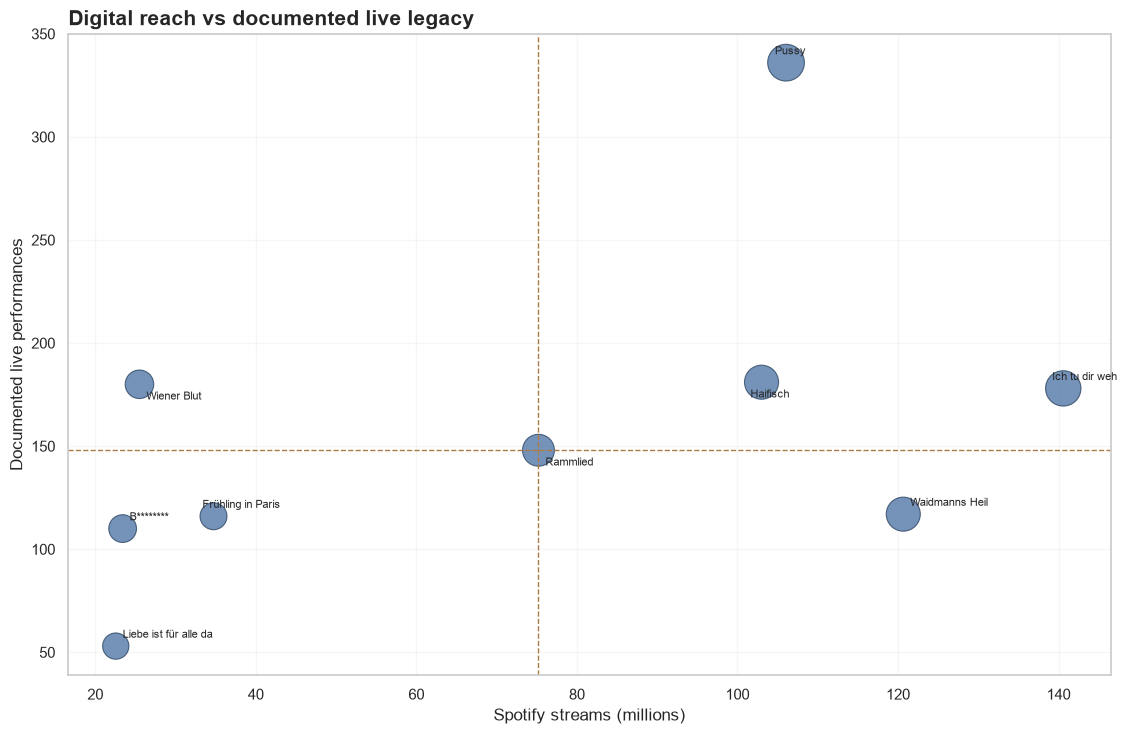

In [15]:
# filtering first keeps unknown live histories outside the stage comparison
live_tracks = tracks.loc[
    tracks["live_count"].notna()
].copy()

digital_mid = live_tracks["spotify_streams"].median()
live_mid = live_tracks["live_count"].median()

size = (
    100
    + 600
    * live_tracks["lastfm_listeners"]
    / live_tracks["lastfm_listeners"].max()
)

fig, ax = plt.subplots(figsize=(11.5, 7.5))

ax.scatter(
    live_tracks["spotify_streams"] / 1_000_000,
    live_tracks["live_count"],
    s=size,
    color="#406a9f",
    edgecolor="#203957",
    linewidth=0.8,
    alpha=0.72,
)

ax.axvline(
    digital_mid / 1_000_000,
    color="#ad7a45",
    linestyle="--",
    linewidth=1,
)

ax.axhline(
    live_mid,
    color="#ad7a45",
    linestyle="--",
    linewidth=1,
)

for i, row in live_tracks.reset_index(drop=True).iterrows():
    ax.annotate(
        row["display_name"],
        (
            row["spotify_streams"] / 1_000_000,
            row["live_count"],
        ),
        xytext=(5 if i % 2 == 0 else -8, 6 if i % 3 else -11),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_xlabel("Spotify streams (millions)")
ax.set_ylabel("Documented live performances")
ax.set_title(
    "Digital reach vs documented live legacy",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.grid(alpha=0.17)

fig.tight_layout()
save_figure(fig, "07_digital_vs_live_legacy.png")
plt.show()

## 13. Stage over-performance can be measured relative to digital scale

Within the documented-live subset, normalized Spotify reach and live count create a simple gap measure. A positive stage gap means the track ranks more strongly on stage than its Spotify scale alone would imply.

In [16]:
# normalization is limited to tracks with documented live counts
live_tracks["digital_score"] = minmax(
    np.log1p(live_tracks["spotify_streams"])
)

live_tracks["stage_score"] = minmax(
    live_tracks["live_count"]
)

live_tracks["stage_gap"] = (
    live_tracks["stage_score"]
    - live_tracks["digital_score"]
)

display(
    live_tracks[
        [
            "track_name",
            "spotify_streams",
            "live_count",
            "digital_score",
            "stage_score",
            "stage_gap",
        ]
    ]
    .sort_values(
        "stage_gap",
        ascending=False
    )
)

,track_name,spotify_streams,live_count,digital_score,stage_score,stage_gap
6,Wiener Blut,25501330,180.000,0.067,0.449,0.382
4,B********,23407374,110.000,0.020,0.201,0.181
7,Pussy,106049284,336.000,0.846,1.000,0.154
8,Liebe ist für alle da,22550422,53.000,0.000,0.000,0.000
5,Frühling in Paris,34726953,116.000,0.236,0.223,-0.013
0,Rammlied,75208799,148.000,0.658,0.336,-0.323
3,Haifisch,102998020,181.000,0.830,0.452,-0.378
1,Ich tu dir weh,140581885,178.000,1.000,0.442,-0.558
2,Waidmanns Heil,120653465,117.000,0.916,0.226,-0.690


## 14. Digital endurance does not require a documented stage history

For tracks with missing live counts, the analysis stays deliberately digital. Their Spotify scale, daily activity and Last.fm behaviour can still be assessed without interpreting missing stage evidence as absence.

In [17]:
# digital-only profiles remain analytically useful even when live evidence is incomplete
undocumented_live = tracks.loc[
    tracks["live_count"].isna(),
    [
        "track_name",
        "edition",
        "spotify_streams",
        "spotify_daily_streams",
        "lastfm_listeners",
        "scrobbles_per_listener",
        "daily_per_million_streams",
    ],
].copy()

display(
    undocumented_live.sort_values(
        "spotify_streams",
        ascending=False
    )
)

,track_name,edition,spotify_streams,spotify_daily_streams,lastfm_listeners,scrobbles_per_listener,daily_per_million_streams
12,Donaukinder,Special Edition,28411732,"12,297.000",140357,9.100,432.814
11,Führe mich,Special Edition,25564873,"7,933.000",124972,8.330,310.309
13,Halt,Special Edition,16991194,"3,276.000",116950,7.950,192.806
9,Mehr,Standard,16799428,"3,555.000",190766,8.110,211.614
10,Roter Sand,Standard,14750579,"2,864.000",186955,7.670,194.162
15,Liese,Special Edition,9587454,"1,421.000",99025,6.370,148.215
14,Roter Sand (Orchester Version),Special Edition,8122161,986.000,31181,6.550,121.396


## 15. Performance count and recency tell different parts of the live story

A song performed many times early in the era is not identical to a song that remained on stage much later. The timeline below places debut, last documented performance and total performance count on the same visual.

saved: 08_live_persistence_timeline.png


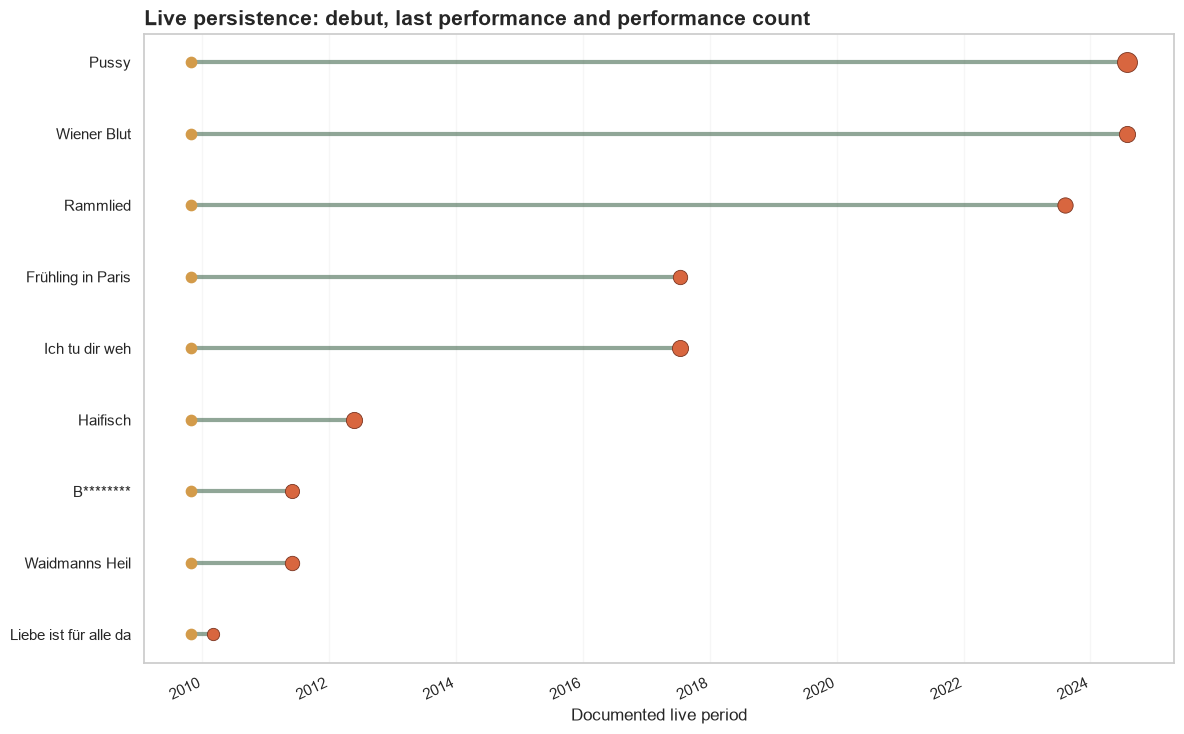

In [18]:
# rows need both endpoints for a meaningful persistence timeline
timeline = (
    live_tracks.dropna(
        subset=["live_debut", "last_performed"]
    )
    .sort_values(
        "last_performed"
    )
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 7.5))

y = np.arange(len(timeline))

for position, (_, row) in enumerate(timeline.iterrows()):
    ax.hlines(
        position,
        row["live_debut"],
        row["last_performed"],
        color="#55765f",
        linewidth=3,
        alpha=0.65,
    )

    ax.scatter(
        row["live_debut"],
        position,
        s=55,
        color="#d39b4a",
        zorder=3,
    )

    ax.scatter(
        row["last_performed"],
        position,
        s=55 + row["live_count"] * 0.45,
        color="#d8663f",
        edgecolor="#7a3420",
        linewidth=0.6,
        zorder=3,
    )

ax.set_yticks(y)
ax.set_yticklabels(timeline["display_name"])
ax.set_xlabel("Documented live period")
ax.set_ylabel("")
ax.set_title(
    "Live persistence: debut, last performance and performance count",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.grid(axis="x", alpha=0.16)
ax.grid(axis="y", visible=False)

fig.autofmt_xdate(rotation=25)
fig.tight_layout()
save_figure(fig, "08_live_persistence_timeline.png")
plt.show()

## 16. Standard and Special Edition tracks can be read as two catalogue groups

The bonus disc is much smaller, so this is a descriptive profile rather than a significance test. Median normalized values keep the comparison from being dominated by one exceptionally large track.

edition,Special Edition,Standard
spotify_reach,0.259,0.510
current_activity,0.348,0.611
lastfm_reach,0.529,0.751
engagement,0.318,0.670


saved: 09_edition_profile_dumbbell.png


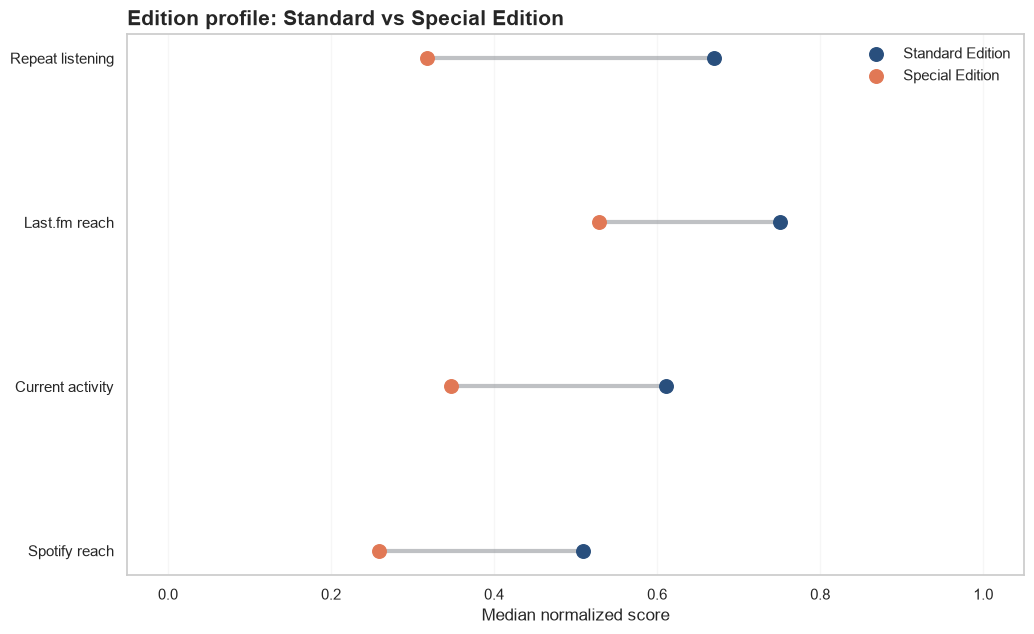

In [19]:
# common digital fields allow a fairer edition comparison than the incomplete live column
edition_metrics = tracks[
    [
        "edition",
        "spotify_streams",
        "spotify_daily_streams",
        "lastfm_listeners",
        "scrobbles_per_listener",
    ]
].copy()

edition_metrics["spotify_reach"] = minmax(
    np.log1p(edition_metrics["spotify_streams"])
)

edition_metrics["current_activity"] = minmax(
    np.log1p(edition_metrics["spotify_daily_streams"])
)

edition_metrics["lastfm_reach"] = minmax(
    np.log1p(edition_metrics["lastfm_listeners"])
)

edition_metrics["engagement"] = minmax(
    edition_metrics["scrobbles_per_listener"]
)

edition_profile = (
    edition_metrics.groupby("edition")[
        [
            "spotify_reach",
            "current_activity",
            "lastfm_reach",
            "engagement",
        ]
    ]
    .median()
    .T
)

display(edition_profile)

fig, ax = plt.subplots(figsize=(10.5, 6.5))

metric_labels = {
    "spotify_reach": "Spotify reach",
    "current_activity": "Current activity",
    "lastfm_reach": "Last.fm reach",
    "engagement": "Repeat listening",
}

metrics = list(edition_profile.index)
y = np.arange(len(metrics))

standard_col = next(
    col for col in edition_profile.columns
    if "Standard" in col
)

special_col = next(
    col for col in edition_profile.columns
    if "Special" in col
)

for position, metric in enumerate(metrics):
    left = edition_profile.loc[metric, standard_col]
    right = edition_profile.loc[metric, special_col]

    ax.hlines(
        position,
        min(left, right),
        max(left, right),
        color="#8b8f94",
        linewidth=3,
        alpha=0.55,
    )

    ax.scatter(
        left,
        position,
        s=95,
        color="#294f7d",
        label="Standard Edition" if position == 0 else None,
        zorder=3,
    )

    ax.scatter(
        right,
        position,
        s=95,
        color="#e17855",
        label="Special Edition" if position == 0 else None,
        zorder=3,
    )

ax.set_yticks(y)
ax.set_yticklabels([metric_labels[m] for m in metrics])
ax.set_xlim(-0.05, 1.05)
ax.set_xlabel("Median normalized score")
ax.set_ylabel("")
ax.set_title(
    "Edition profile: Standard vs Special Edition",
    loc="left",
    fontsize=15,
    fontweight="bold",
)
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.16)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "09_edition_profile_dumbbell.png")
plt.show()

## 17. Musical attributes are exploratory signals, not explanations

Tempo, duration and key may coincide with audience behaviour, but sixteen observations are far too few for strong causal claims. Spearman relationships are therefore used as pattern-finding tools, while key-level summaries stay descriptive.

In [20]:
# numeric musical features are paired with audience outcomes through rank correlation
musical_features = [
    "bpm",
    "duration_sec",
]

audience_outcomes = [
    "spotify_streams",
    "spotify_daily_streams",
    "lastfm_listeners",
    "scrobbles_per_listener",
]

relationship_rows = []

for feature in musical_features:
    for outcome in audience_outcomes:
        rho = (
            tracks[[feature, outcome]]
            .corr(method="spearman")
            .iloc[0, 1]
        )

        relationship_rows.append({
            "feature": feature,
            "outcome": outcome,
            "spearman_rho": rho,
        })

musical_relationships = (
    pd.DataFrame(relationship_rows)
    .sort_values(
        "spearman_rho",
        key=lambda s: s.abs(),
        ascending=False
    )
)

display(musical_relationships)

key_summary = (
    tracks.groupby("key")
    .agg(
        tracks=("track_name", "size"),
        median_spotify=("spotify_streams", "median"),
        median_daily=("spotify_daily_streams", "median"),
        median_engagement=("scrobbles_per_listener", "median"),
    )
    .sort_values(
        "tracks",
        ascending=False
    )
)

display(key_summary)

,feature,outcome,spearman_rho
2,bpm,lastfm_listeners,0.729
3,bpm,scrobbles_per_listener,0.713
1,bpm,spotify_daily_streams,0.600
0,bpm,spotify_streams,0.600
4,duration_sec,spotify_streams,0.169
5,duration_sec,spotify_daily_streams,0.168
6,duration_sec,lastfm_listeners,-0.103
7,duration_sec,scrobbles_per_listener,0.066


,tracks,median_spotify,median_daily,median_engagement
key,,,,
D minor,8,"51,810,265.500","14,471.000",9.415
E minor,5,"14,750,579.000","2,864.000",7.670
D,2,"20,103,401.000","4,359.000",8.305
F-sharp minor,1,"34,726,953.000","8,119.000",9.700


## 18. Legacy works better as a profile than as a single unquestioned score

No one metric can define a track's afterlife. Five normalized dimensions form a “legacy fingerprint”: Spotify reach, current activity, Last.fm reach, repeat listening and documented live presence. Missing live evidence remains visibly missing in the heatmap, while combined scoring is restricted to tracks with documented live counts.

A second check changes the weights. If the ranking changes dramatically, the framework is sensitive and should be presented as such rather than as an objective truth.

saved: 10_legacy_fingerprint_heatmap.png


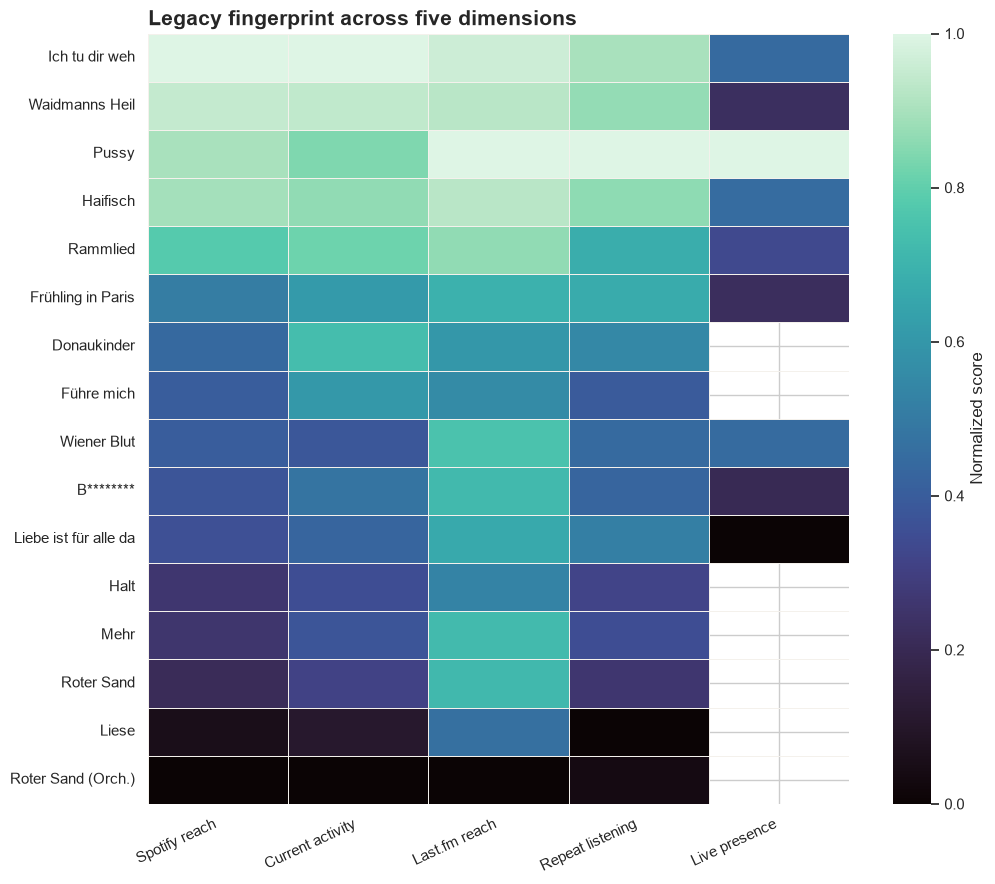

,track_name,digital_legacy_score,balanced_legacy_score
1,Ich tu dir weh,0.966,0.861
7,Pussy,0.936,0.949
2,Waidmanns Heil,0.920,0.782
3,Haifisch,0.886,0.799
0,Rammlied,0.785,0.695
5,Frühling in Paris,0.620,0.541
12,Donaukinder,0.580,NaN
4,B********,0.500,0.440
6,Wiener Blut,0.494,0.485
8,Liebe ist für alle da,0.492,0.393


In [21]:
# logarithmic scaling keeps very large stream counts from overwhelming smaller dimensions
legacy = tracks[
    [
        "track_name",
        "display_name",
        "spotify_streams",
        "spotify_daily_streams",
        "lastfm_listeners",
        "scrobbles_per_listener",
        "live_count",
    ]
].copy()

legacy["spotify_reach"] = minmax(
    np.log1p(legacy["spotify_streams"])
)

legacy["current_activity"] = minmax(
    np.log1p(legacy["spotify_daily_streams"])
)

legacy["lastfm_reach"] = minmax(
    np.log1p(legacy["lastfm_listeners"])
)

legacy["repeat_listening"] = minmax(
    legacy["scrobbles_per_listener"]
)

legacy["live_presence"] = minmax(
    legacy["live_count"]
)

fingerprint_columns = [
    "spotify_reach",
    "current_activity",
    "lastfm_reach",
    "repeat_listening",
    "live_presence",
]

legacy["digital_legacy_score"] = (
    legacy[
        [
            "spotify_reach",
            "current_activity",
            "lastfm_reach",
            "repeat_listening",
        ]
    ]
    .mean(axis=1)
)

documented_mask = legacy["live_presence"].notna()

legacy.loc[
    documented_mask,
    "balanced_legacy_score"
] = (
    legacy.loc[
        documented_mask,
        fingerprint_columns
    ]
    .mean(axis=1)
)

heatmap_data = (
    legacy.set_index("display_name")[
        fingerprint_columns
    ]
    .sort_values(
        "spotify_reach",
        ascending=False
    )
)

fig, ax = plt.subplots(figsize=(10.5, 9))

sns.heatmap(
    heatmap_data,
    cmap="mako",
    vmin=0,
    vmax=1,
    linewidths=0.6,
    linecolor="#f4f1ec",
    cbar_kws={"label": "Normalized score"},
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(
    [
        "Spotify reach",
        "Current activity",
        "Last.fm reach",
        "Repeat listening",
        "Live presence",
    ],
    rotation=25,
    ha="right",
)

ax.set_title(
    "Legacy fingerprint across five dimensions",
    loc="left",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout()
save_figure(fig, "10_legacy_fingerprint_heatmap.png")
plt.show()

display(
    legacy[
        [
            "track_name",
            "digital_legacy_score",
            "balanced_legacy_score",
        ]
    ]
    .sort_values(
        "digital_legacy_score",
        ascending=False
    )
)

In [22]:
# three weighting schemes reveal how stable the documented-live ranking really is
documented_legacy = legacy.loc[
    documented_mask
].copy()

weight_scenarios = {
    "balanced": {
        "spotify_reach": 0.20,
        "current_activity": 0.20,
        "lastfm_reach": 0.20,
        "repeat_listening": 0.20,
        "live_presence": 0.20,
    },
    "digital_heavy": {
        "spotify_reach": 0.30,
        "current_activity": 0.25,
        "lastfm_reach": 0.20,
        "repeat_listening": 0.15,
        "live_presence": 0.10,
    },
    "live_heavy": {
        "spotify_reach": 0.15,
        "current_activity": 0.15,
        "lastfm_reach": 0.10,
        "repeat_listening": 0.10,
        "live_presence": 0.50,
    },
}

for scenario, weights in weight_scenarios.items():
    documented_legacy[f"{scenario}_score"] = sum(
        documented_legacy[column] * weight
        for column, weight in weights.items()
    )

    documented_legacy[f"{scenario}_rank"] = (
        documented_legacy[f"{scenario}_score"]
        .rank(
            ascending=False,
            method="min"
        )
    )

sensitivity_columns = [
    "track_name",
    "balanced_rank",
    "digital_heavy_rank",
    "live_heavy_rank",
    "balanced_score",
    "digital_heavy_score",
    "live_heavy_score",
]

display(
    documented_legacy[sensitivity_columns]
    .sort_values("balanced_rank")
)

,track_name,balanced_rank,digital_heavy_rank,live_heavy_rank,balanced_score,digital_heavy_score,live_heavy_score
7,Pussy,1.000,1.000,1.000,0.949,0.931,0.962
1,Ich tu dir weh,2.000,2.000,2.000,0.861,0.922,0.707
3,Haifisch,3.000,4.000,3.000,0.799,0.844,0.668
2,Waidmanns Heil,4.000,3.000,4.000,0.782,0.857,0.575
0,Rammlied,5.000,5.000,5.000,0.695,0.747,0.562
5,Frühling in Paris,6.000,6.000,7.000,0.541,0.566,0.415
6,Wiener Blut,7.000,7.000,6.000,0.485,0.477,0.461
4,B********,8.000,8.000,8.000,0.440,0.460,0.343
8,Liebe ist für alle da,9.000,9.000,9.000,0.393,0.425,0.236


## Closing analytical note

The strongest portfolio story should come from the relationships that survive scrutiny, not from forcing every question into a dramatic conclusion. With only sixteen tracks, effect size, direction, missing-data treatment and context matter more than statistical theatre.

The exported `visuals/` folder now provides a clean set of ten figures that can later be reused in the website, README or presentation without rebuilding them manually.